# 06 · Absorption and stripping

Gas absorption removes a component from a gas by dissolving it in a liquid; stripping does the reverse.
Sweetening natural gas, capturing CO$_2$ from flue gas, scrubbing SO$_2$, recovering solvents: the equipment
is a countercurrent column of trays or packing, and for dilute systems with a linear equilibrium line the
Kremser equation gives the answer in closed form. This notebook designs a tray absorber and a stripper, finds
the minimum solvent rate, and shows the absorption factor as the single number that controls both.

**What you will learn**
- use the absorption factor and the Kremser equation
- find the minimum solvent rate and choose a design rate
- step stages on the operating diagram
- design a stripper and relate m to Henry's law and pressure

**Before you start:** notebook 03  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import absorption as ab
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The absorption factor and the Kremser equation

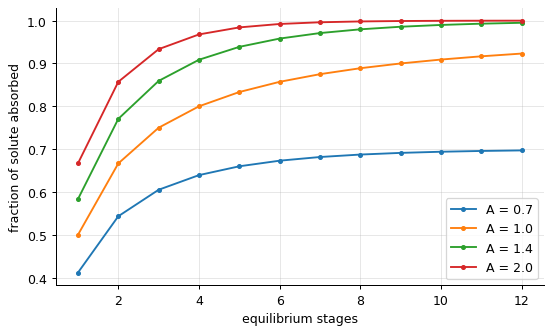

A = 0.7: fraction absorbed with 6 stages 0.673, with 100 stages 0.700
A = 1.4: fraction absorbed with 6 stages 0.958, with 100 stages 1.000


In [2]:
m = 0.8                                                            # equilibrium y = m x (Henry's law in mole-fraction form)
V, y_in = 100.0, 0.02                                               # kmol/h of carrier gas, 2 % solute
fig, ax = plt.subplots()
Ns = np.arange(1, 13)
for A in (0.7, 1.0, 1.4, 2.0):
    ax.plot(Ns, [ab.kremser_fraction_absorbed(A, N) for N in Ns], "o-", ms=3, label=f"A = {A}")
ax.set(xlabel="equilibrium stages", ylabel="fraction of solute absorbed"); ax.legend(); plt.show()
for A in (0.7, 1.4):
    print(f"A = {A}: fraction absorbed with 6 stages {ab.kremser_fraction_absorbed(A, 6):.3f}, with 100 stages {ab.kremser_fraction_absorbed(A, 100):.3f}")

The absorption factor $A = L/(mV)$ compares the solvent's capacity with the gas load. Below 1 the solvent
cannot absorb everything however many stages are added (the limit is $A$ itself); above 1 recovery approaches
100 % with enough stages; at $A \approx 1.4$ the curve bends where more stages stop paying - Kremser's
equation, and the whole economics of absorption, in one plot.

## Designing a tray absorber

In [3]:
recovery = 0.95
y_out = y_in * (1 - recovery)
L_min = ab.minimum_solvent(V, y_in, y_out, m)
print(f"minimum solvent for {recovery:.0%} recovery: L_min = {L_min:.1f} kmol/h (A = {ab.absorption_factor(L_min, V, m):.3f})")
for factor in (1.2, 1.5, 2.0):
    L = factor * L_min
    A = ab.absorption_factor(L, V, m)
    N = ab.kremser_stages(A, recovery)
    print(f"L = {factor} L_min = {L:6.1f} kmol/h: A = {A:.2f}, stages = {N:.2f} -> {int(np.ceil(N))} trays")
st = ab.stages_absorber(lambda x: m * x, 1.5 * L_min, V, y_in, y_out)
print(f"\nstage-by-stage at 1.5 L_min: {st['stages']} stages, rich solvent x_out = {st['x_out']:.4f}")

minimum solvent for 95% recovery: L_min = 76.0 kmol/h (A = 0.950)
L = 1.2 L_min =   91.2 kmol/h: A = 1.14, stages = 9.19 -> 10 trays
L = 1.5 L_min =  114.0 kmol/h: A = 1.43, stages = 5.36 -> 6 trays
L = 2.0 L_min =  152.0 kmol/h: A = 1.90, stages = 3.59 -> 4 trays

stage-by-stage at 1.5 L_min: 6 stages, rich solvent x_out = 0.0217


The minimum solvent rate makes the operating line touch the equilibrium line at the rich end (a pinch:
infinite stages); 1.2-2 times the minimum is the usual design range, and each increase in solvent trades
trays for pumping and regeneration cost. Stepping stages by hand (equilibrium, then operating line, like
McCabe-Thiele) reproduces the Kremser count.

## The operating diagram

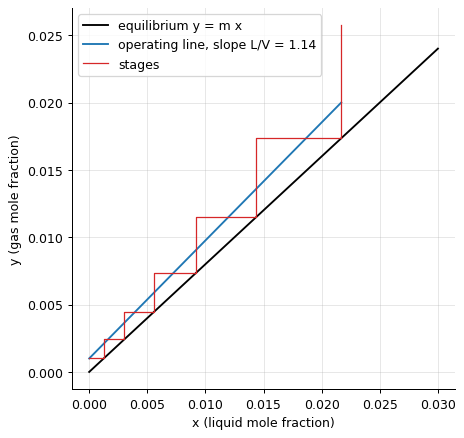

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
xs = np.linspace(0, 0.03, 50)
ax.plot(xs, m * xs, "k", label="equilibrium y = m x")
L = 1.5 * L_min
ax.plot([0, st["x_out"]], [y_out, y_in], "C0", label=f"operating line, slope L/V = {L/V:.2f}")
ax.step(st["x"], st["y"], "C3", where="post", lw=1, label="stages")
ax.set(xlabel="x (liquid mole fraction)", ylabel="y (gas mole fraction)"); ax.legend(); plt.show()

For absorption the operating line lies *above* the equilibrium line (the gas is richer than equilibrium with
the liquid, so solute moves gas to liquid); for stripping it lies below. The stages step between them from
the lean end, and the closer the lines the more stages: the pinch again.

## Stripping: the same equation upside down

In [5]:
x_in, x_out_target = 0.01, 0.0005                                    # rich solvent in, 95 % stripped
L = 100.0
V_min = L / m * 0.95                                                  # the stripping gas must carry S > phi: V_min = phi L/m... for 95 % stripping S must exceed 0.95
print(f"stripping 95 % of the solute from {L} kmol/h of solvent (m = {m}) needs S = m V/L > 0.95, i.e. V > {V_min:.0f} kmol/h of gas")
for V_strip in (150.0, 200.0, 400.0):
    S = ab.stripping_factor(L, V_strip, m)
    print(f"V = {V_strip:.0f} kmol/h: S = {S:.2f}, stages = {ab.kremser_stages(S, 1 - x_out_target / x_in):.1f}")
try:
    ab.kremser_stages(ab.stripping_factor(L, 30.0, m), 0.95)
except ValueError as e:
    print("V = 30 kmol/h:", e)

stripping 95 % of the solute from 100.0 kmol/h of solvent (m = 0.8) needs S = m V/L > 0.95, i.e. V > 119 kmol/h of gas
V = 150 kmol/h: S = 1.20, stages = 7.8
V = 200 kmol/h: S = 1.60, stages = 4.5
V = 400 kmol/h: S = 3.20, stages = 2.3
V = 30 kmol/h: A fraction of 0.95 cannot be absorbed with A = 0.24 < 1: the limit with infinite stages is A.


The stripping factor $S = mV/L$ is the absorption factor inverted, and the Kremser equation applies with
the roles of gas and liquid exchanged - including the limit: with $S < 1$ the gas cannot carry the solute
away however many stages there are, and the library says so rather than returning nonsense. Absorber and stripper are usually a pair - the solvent circulates
between them - and the overall design balances solvent rate, stages in each, and the energy to regenerate,
which is what makes amine CO$_2$ capture expensive.

## Temperature and pressure: where the slope m comes from

In [6]:
H = {"CO2": 1640.0, "H2S": 550.0, "SO2": 40.0, "NH3": 0.9}         # Henry's constants in water at 25 degC, bar (mole-fraction basis, approximate)
for P_bar in (1.0, 10.0, 50.0):
    print(f"P = {P_bar:4.0f} bar: " + ", ".join(f"{g}: m = {ab.henry_slope(Hc, P_bar):8.1f}" for g, Hc in H.items()))

P =    1 bar: CO2: m =   1640.0, H2S: m =    550.0, SO2: m =     40.0, NH3: m =      0.9
P =   10 bar: CO2: m =    164.0, H2S: m =     55.0, SO2: m =      4.0, NH3: m =      0.1
P =   50 bar: CO2: m =     32.8, H2S: m =     11.0, SO2: m =      0.8, NH3: m =      0.0


The equilibrium slope $m = H/P$ falls with pressure, so absorbing at high pressure raises the absorption
factor and cuts the solvent rate - which is why gas sweetening runs at pipeline pressure. CO$_2$ in water has
an enormous Henry's constant (physical absorption is hopeless at 1 bar); ammonia's is tiny (water scrubs it
easily); SO$_2$ sits between. Chemical solvents like amines change the picture by reacting with the solute,
lowering the effective $m$ by orders of magnitude.

## Inside the algorithm: the Kremser equation

In [7]:
A_, N_ = 1.4, 6
print("by hand:", (A_ ** (N_ + 1) - A_) / (A_ ** (N_ + 1) - 1), "; library:", ab.kremser_fraction_absorbed(A_, N_))

by hand: 0.9580772130536155 ; library: 0.9580772130536155


## Exercises
1. An absorber must remove 99 % of the SO2 (1.5 mol %) from 200 kmol/h of flue gas with water at 1 atm (m = 40 at 25 degC). Find L_min, the stages at 1.5 L_min, and then repeat at 10 degC (m = 25) and 40 degC (m = 70). Why do scrubbers run cold?
2. The rich solvent (x = 0.01) is stripped with air. Plot the stages needed against the stripping factor from 1.2 to 5 for 95 and 99 % stripping. Where does adding stripping gas stop paying?
3. **Implement it yourself:** write a stage-by-stage absorber (equilibrium, then operating line) for a linear equilibrium and reproduce the Kremser stage count for A = 1.4 and 95 % recovery.